<h1>IMPORTAÇÃO DE BIBLIOTECAS</h1>

In [6]:
import pandas as pd
import numpy as np

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


import seaborn as sns

<h2> B) Correlação dos dados - Remoção de Features altamente correlacionadas </h2>

In [7]:
preprocessing_path = "./preprocessing/"

features_dataset_filename = "04-features_dataset.csv"
preprocessing_dataset_fileName = "05-preprocessing_dataset.csv"

df_features_dataset = pd.read_csv(preprocessing_path+features_dataset_filename)

In [8]:
time_columns = [ 'I_amplitude',
       'I_energy', 'I_kurtosis', 'I_max', 'I_mean', 'I_median', 'I_min',
       'I_mode', 'I_rms', 'I_skewness', 'I_std', 'I_variance', 'Q_amplitude',
       'Q_energy', 'Q_kurtosis', 'Q_max', 'Q_mean', 'Q_median', 'Q_min',
       'Q_mode', 'Q_rms', 'Q_skewness', 'Q_std', 'Q_variance',
       'module_amplitude', 'module_energy', 'module_kurtosis', 'module_max',
       'module_mean', 'module_median', 'module_min', 'module_mode',
       'module_rms', 'module_skewness', 'module_std', 'module_variance',
       'fase_amplitude', 'fase_energy', 'fase_kurtosis', 'fase_max',
       'fase_mean', 'fase_median', 'fase_min', 'fase_mode', 'fase_rms',
       'fase_skewness', 'fase_std', 'fase_variance']

time_columns_removidas = ["I_mean", "Q_mean", "Q_median", "Q_rms", "module_energy",
"module_mean", "module_median", "module_rms", "fase_std",
"fase_variance",
"fase_median",
"Q_variance",
"Q_energy",
"I_rms", "I_energy"]

freq_columns = ['fft_bandwidth',
       'fft_dominant_frequency', 'fft_dominant_frequency_magnitude',
       'fft_energy_spectral', 'fft_frequency_mean', 'fft_frequency_median',
       'fft_kurtosis', 'fft_skewness']

freq_columns_removidas = ['fft_dominant_frequency', 'fft_dominant_frequency_magnitude', 'fft_energy_spectral']

columns_filtradas = [
    col for col in freq_columns+time_columns
    if col not in freq_columns_removidas + time_columns_removidas
]


class_column = ['class']

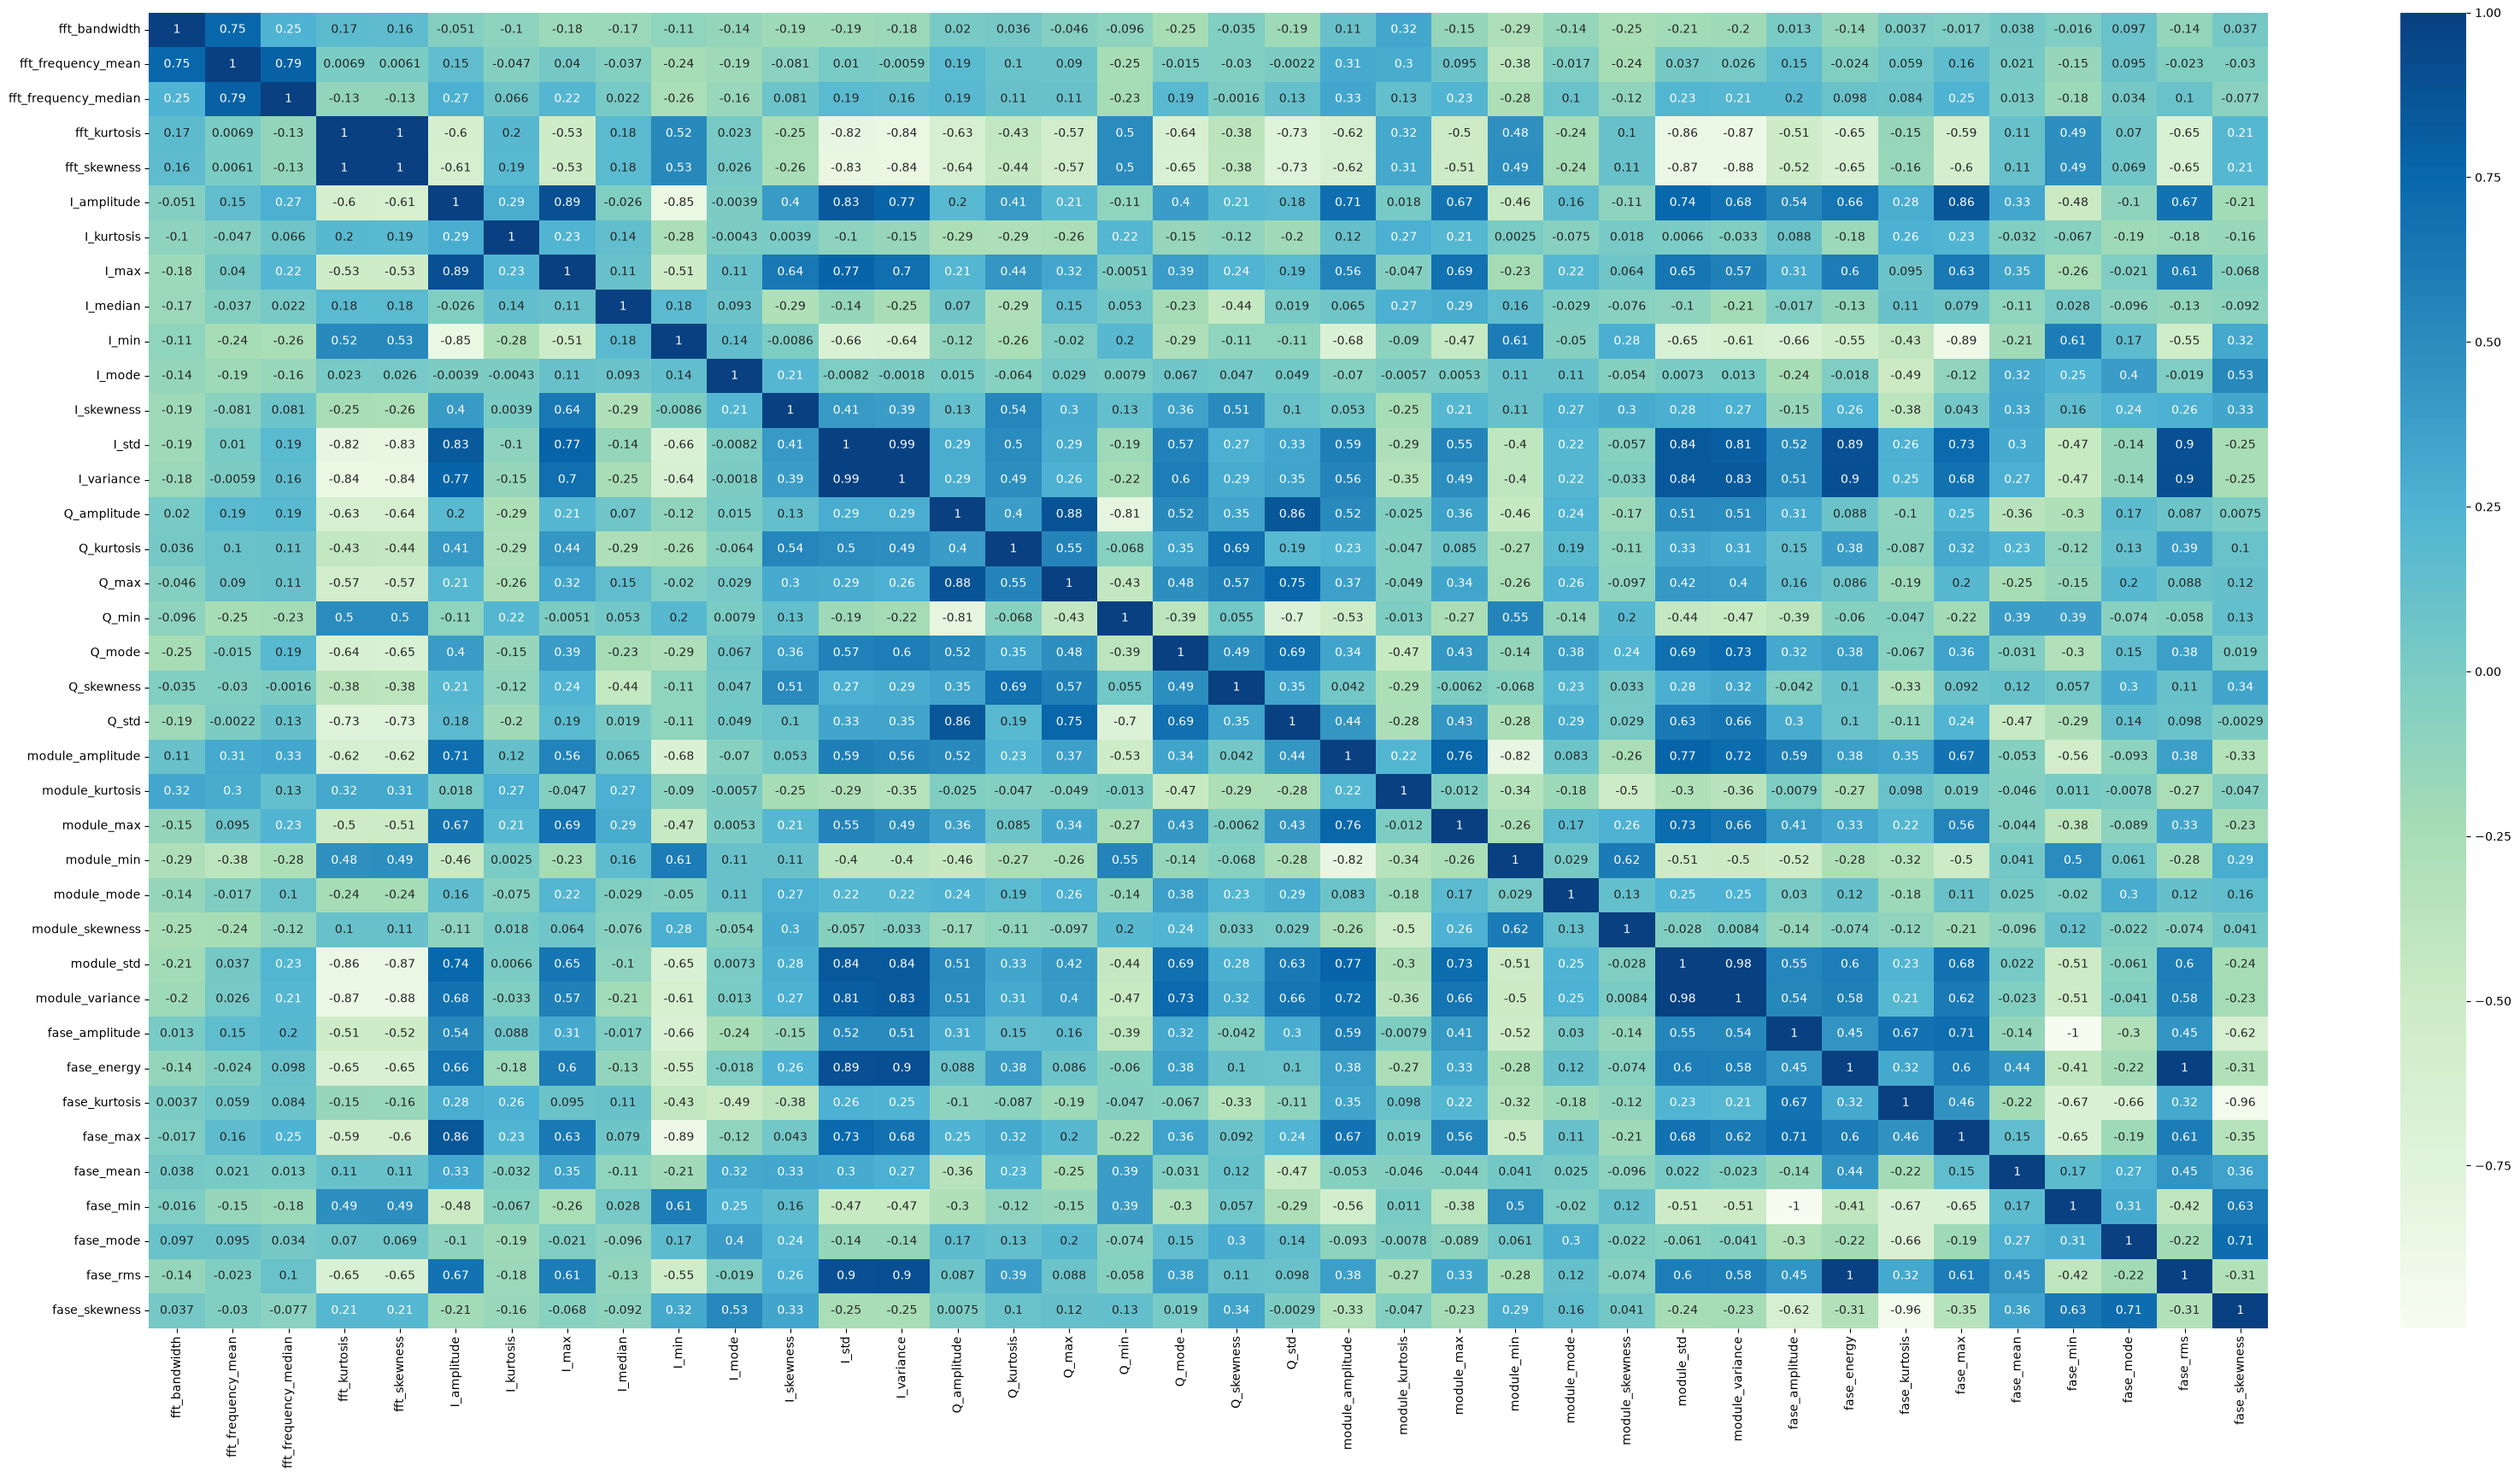

In [9]:
%matplotlib inline

data_numeric = df_features_dataset.select_dtypes(include="number")

def heatmap_corr(data):
    plt.rcParams['figure.figsize'] = [40, 20]
    sns.heatmap(data.corr(),
                annot=True,
                cmap="GnBu"
    )
    

data_numeric = df_features_dataset[columns_filtradas].select_dtypes(include="number")
heatmap_corr(data_numeric)

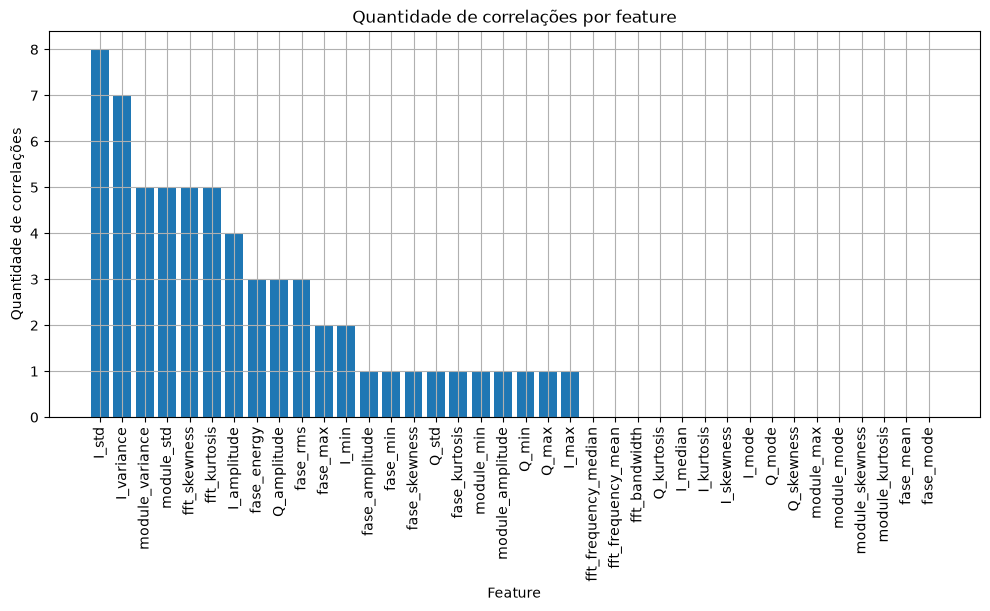

Features removidas:
I_amplitude
I_energy
I_mean
I_min
I_rms
I_std
I_variance
Q_amplitude
Q_energy
Q_mean
Q_median
Q_rms
Q_variance
fase_median
fase_min
fase_rms
fase_skewness
fase_std
fase_variance
fft_dominant_frequency
fft_dominant_frequency_magnitude
fft_energy_spectral
fft_kurtosis
fft_skewness
module_amplitude
module_energy
module_mean
module_median
module_rms
module_variance


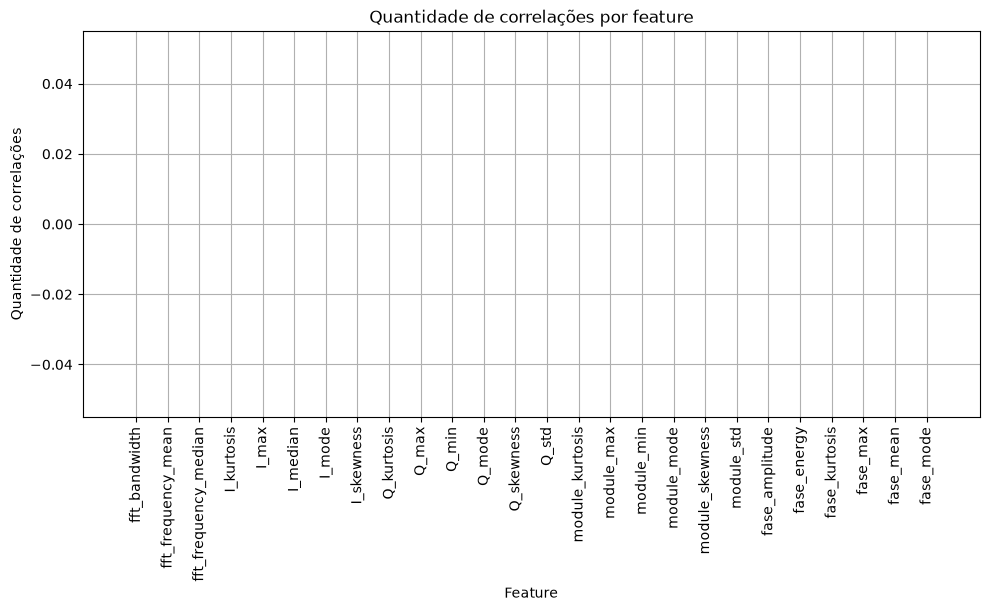

(13830, 31)


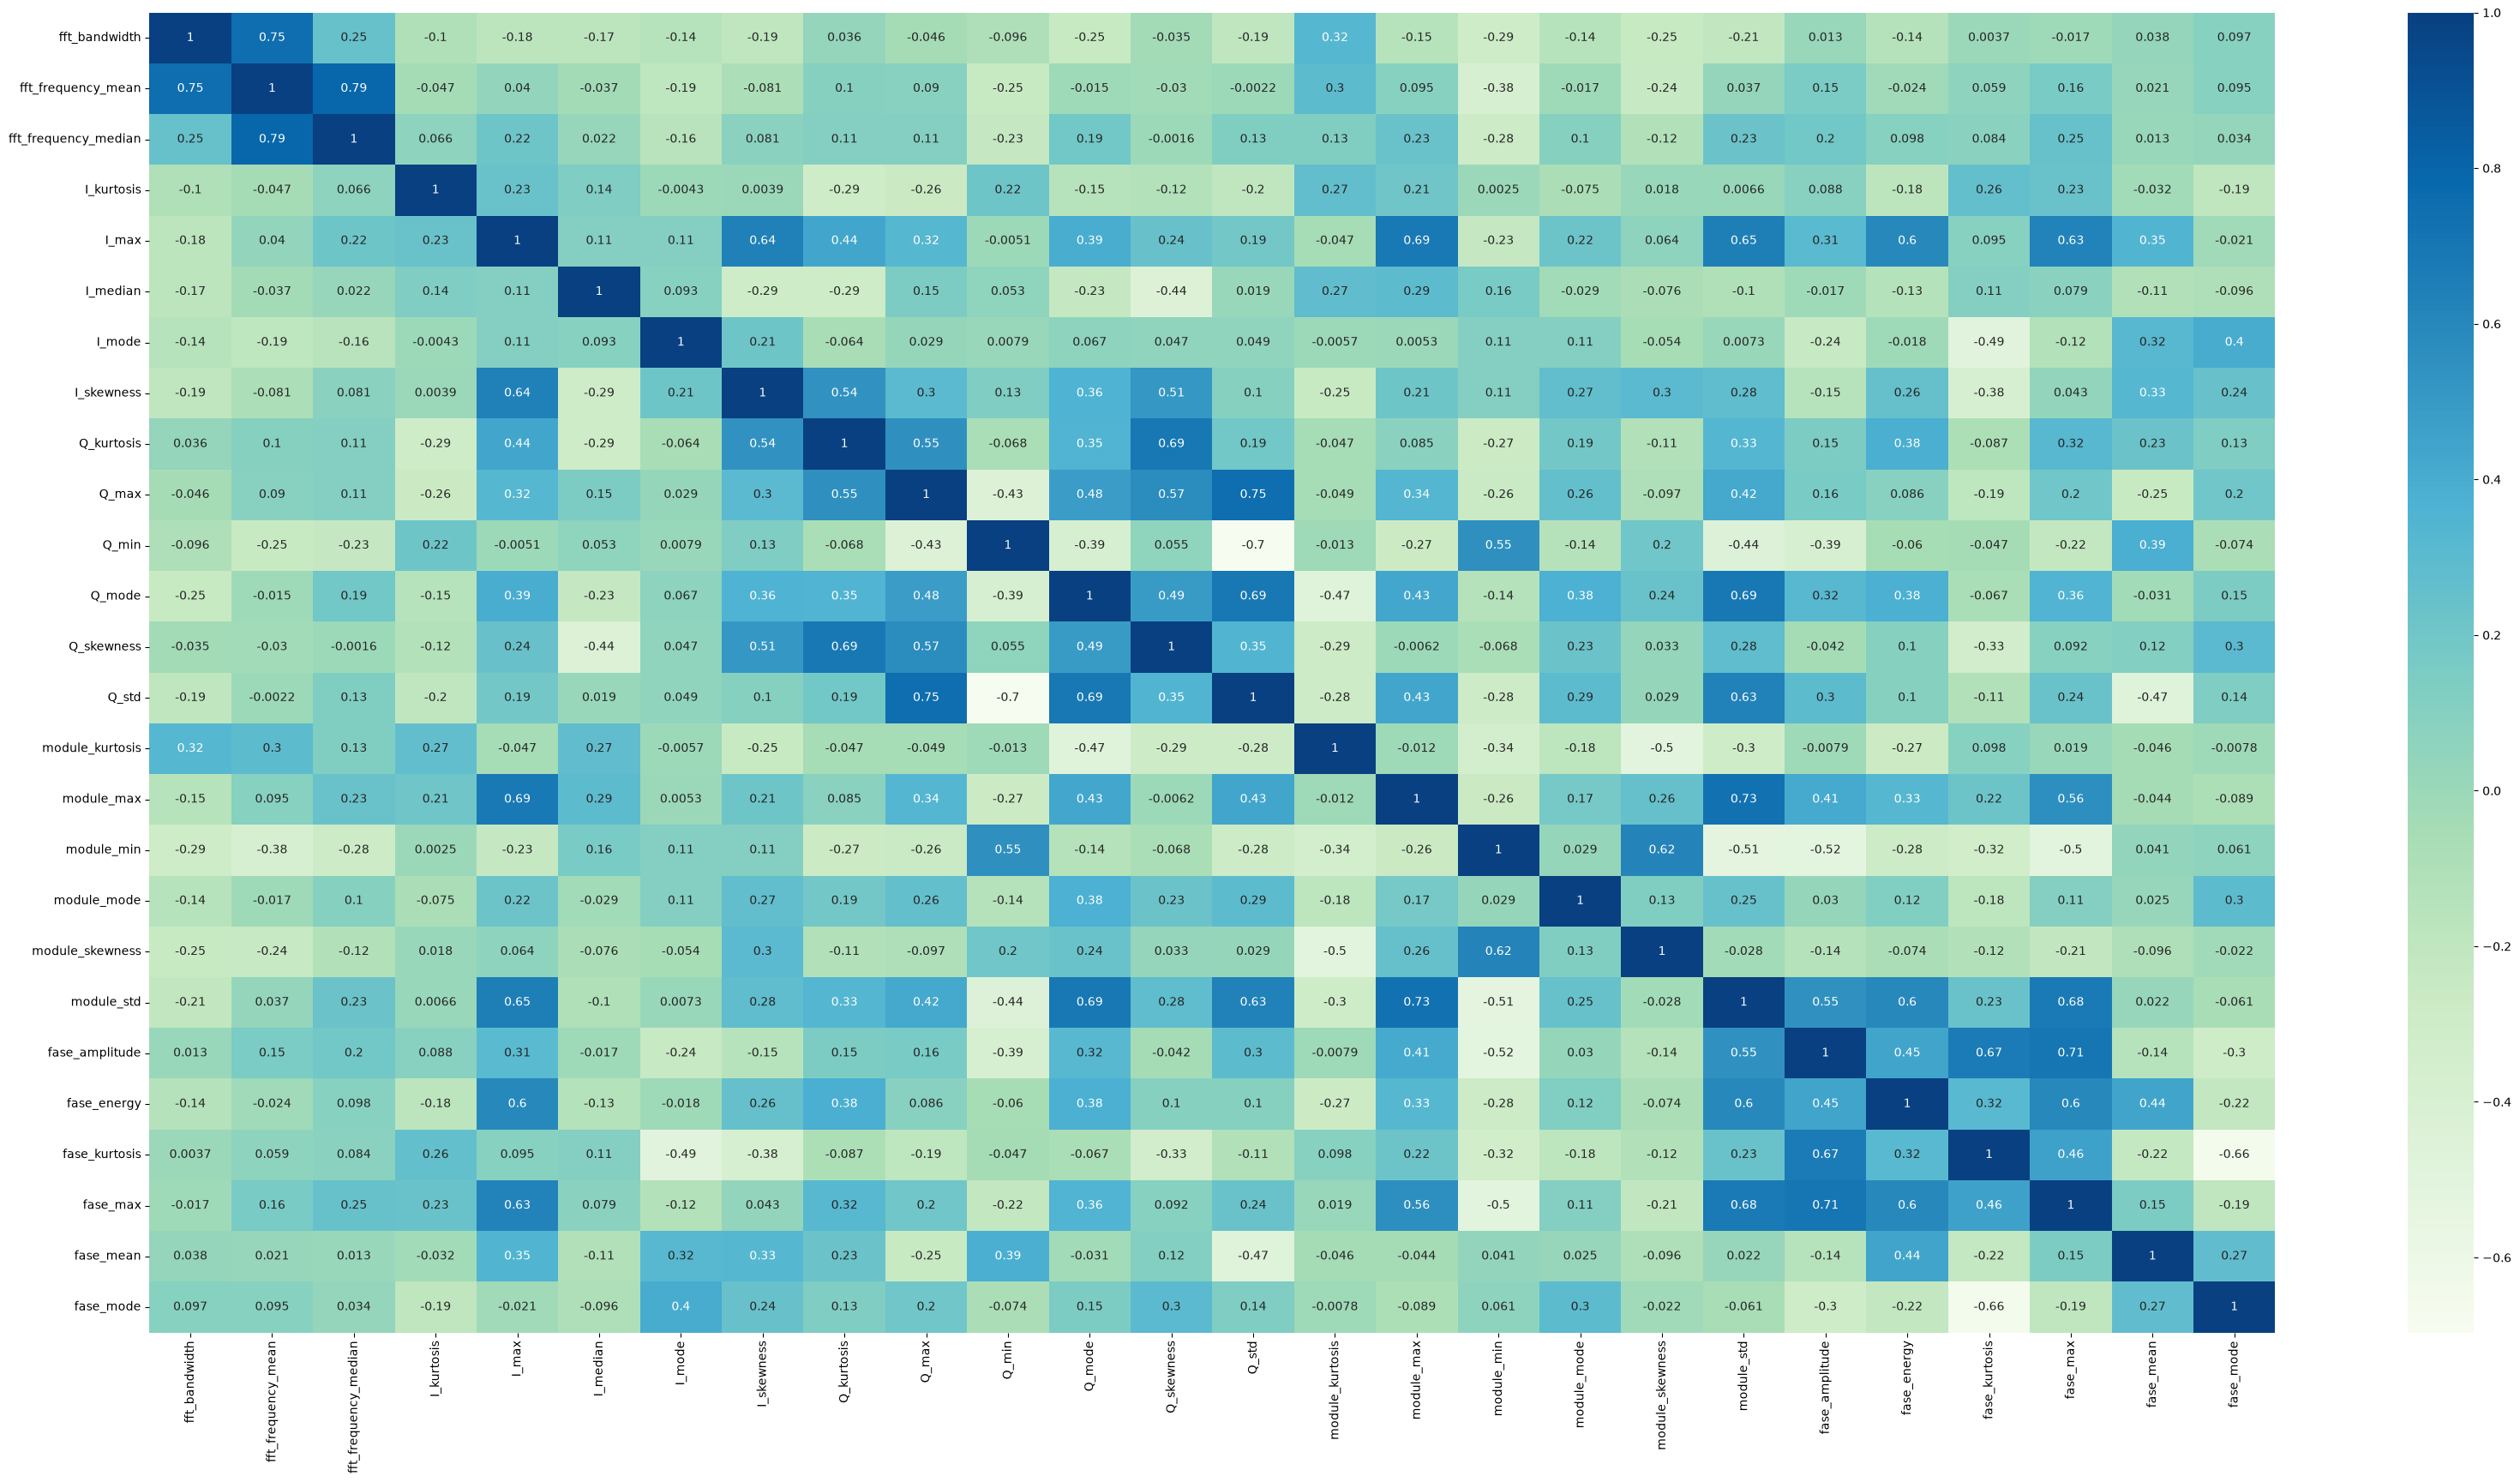

In [10]:
%matplotlib inline

max_high_correlation = 0
hate_high_correlation = 0.8

def count_high_correlation(data):
    mask = np.abs(data) >= hate_high_correlation
    return np.count_nonzero(mask)-1

def max_count_high_correlation(data):
    matriz_corr = data.corr()
    return np.max(matriz_corr.apply(count_high_correlation).sort_values(ascending=False))

def figure_corr(data):
    matriz_corr = data.corr()
    quantity_high_correlation = matriz_corr.apply(count_high_correlation).sort_values(ascending=False)
    plt.figure(figsize=(10, 6))
    plt.grid(True)
    plt.bar(quantity_high_correlation.index, quantity_high_correlation.values)
    plt.xticks(rotation=90)
    plt.ylabel("Quantidade de correlações")
    plt.xlabel("Feature")
    plt.tight_layout()
    plt.title("Quantidade de correlações por feature")
    plt.show()

def drop_high_correlation_feature(data):
    matriz_corr = data.corr()
    quantity_high_correlation = matriz_corr.apply(count_high_correlation).sort_values(ascending=False)
    feature_to_drop = quantity_high_correlation.index[0]
    return feature_to_drop, data.drop(columns=[feature_to_drop])


features_dropped = [] + freq_columns_removidas + time_columns_removidas

data_numeric_reduzido = data_numeric[columns_filtradas].copy()

# Retirando features com alta correlação
figure_corr(data_numeric_reduzido)

features_removed = []
while max_count_high_correlation(data_numeric_reduzido) > max_high_correlation:
    feature_dropped, data_numeric_reduzido = drop_high_correlation_feature(data_numeric_reduzido)
    features_removed.append(feature_dropped)

features_dropped.extend(features_removed)
print("Features removidas:\n" + '\n'.join(sorted(features_dropped)))

figure_corr(data_numeric_reduzido)
heatmap_corr(data_numeric_reduzido)

df_features_reduzido = df_features_dataset.drop(columns=features_dropped)

print(df_features_reduzido.shape)
df_features_reduzido.to_csv(preprocessing_path+preprocessing_dataset_fileName, index=False)



In [24]:
cols_df1 = set(df_features_reduzido.select_dtypes('number').columns)
cols_df2 = set(data_numeric_reduzido.select_dtypes('number').columns)

print("Colunas em df_features_reduzido e não em data_numeric_reduzido:")
print(cols_df1 - cols_df2)

print("\nColunas em data_numeric_reduzido e não em df_features_reduzido:")
print(cols_df2 - cols_df1)

Colunas em df_features_reduzido e não em data_numeric_reduzido:
{'motorSpeed', 'load'}

Colunas em data_numeric_reduzido e não em df_features_reduzido:
set()


In [25]:
df_features_reduzido.select_dtypes('number').columns

Index(['motorSpeed', 'load', 'I_kurtosis', 'I_max', 'I_median', 'I_mode',
       'I_skewness', 'Q_kurtosis', 'Q_max', 'Q_min', 'Q_mode', 'Q_skewness',
       'Q_std', 'module_kurtosis', 'module_max', 'module_min', 'module_mode',
       'module_skewness', 'module_std', 'fase_amplitude', 'fase_energy',
       'fase_kurtosis', 'fase_max', 'fase_mean', 'fase_mode', 'fft_bandwidth',
       'fft_frequency_mean', 'fft_frequency_median'],
      dtype='str')